In [2]:
import pandas as pd
import time

file = "SpectrumData_2021Y.xlsx"

sheets = ["wavelength", "darkcurrent", "trainSet", "testSetLowNoise"]
data = {}

for sheet in sheets:
    start = time.time()
    print(f"Loading {sheet}...", flush=True)

    data[sheet] = pd.read_excel(file, sheet_name=sheet)

    print(
        f"Loaded {sheet}: {data[sheet].shape} "
        f"in {time.time() - start:.1f} seconds",
        flush=True
    )

wavelength = data["wavelength"]
darkcurrent = data["darkcurrent"]
trainSet = data["trainSet"]
testSetLowNoise = data["testSetLowNoise"]

Loading wavelength...
Loaded wavelength: (224, 3) in 0.1 seconds
Loading darkcurrent...
Loaded darkcurrent: (640, 224) in 0.4 seconds
Loading trainSet...
Loaded trainSet: (50000, 227) in 36.1 seconds
Loading testSetLowNoise...
Loaded testSetLowNoise: (100000, 227) in 75.1 seconds


Device: cpu
Device: cpu
Architecture: 224 → 64 → 32 → 5
Training rows: 50,000
Spatial clusters: 60
Validation folds: 5

Training validation fold 1/5
Epoch   1 | train loss 0.6955 | validation F1 0.8515
Epoch  10 | train loss 0.0072 | validation F1 0.9880
Epoch  20 | train loss 0.0018 | validation F1 0.9979
Epoch  30 | train loss 0.0011 | validation F1 0.9963
Epoch  40 | train loss 0.0009 | validation F1 0.9959
Early stopping at epoch 40

Training validation fold 2/5
Epoch   1 | train loss 0.7484 | validation F1 0.9002
Epoch  10 | train loss 0.0072 | validation F1 0.9968
Epoch  20 | train loss 0.0014 | validation F1 0.9974
Epoch  30 | train loss 0.0016 | validation F1 0.9982
Early stopping at epoch 36

Training validation fold 3/5
Epoch   1 | train loss 0.7565 | validation F1 0.8498
Epoch  10 | train loss 0.0079 | validation F1 0.9804
Epoch  20 | train loss 0.0014 | validation F1 0.9873
Epoch  30 | train loss 0.0021 | validation F1 0.9918
Epoch  40 | train loss 0.0007 | validation F1 0.

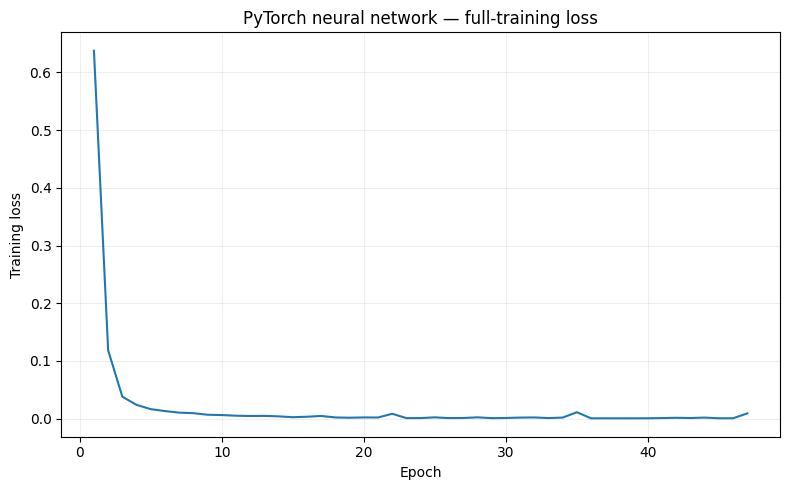

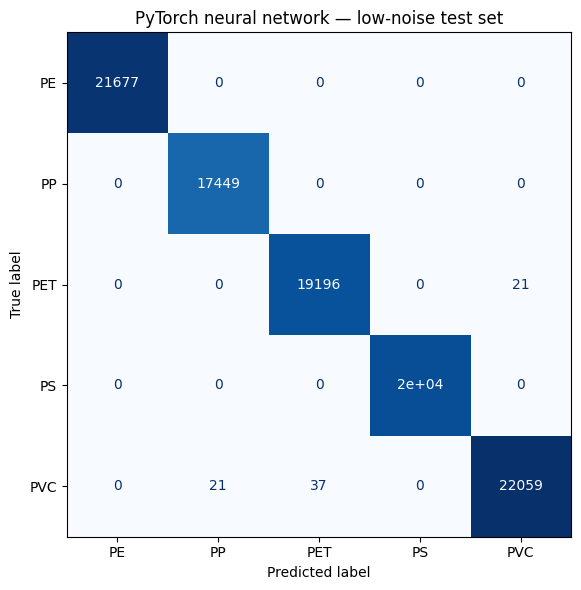


Test metrics:
test_accuracy: 0.9992
test_macro_precision: 0.9992
test_macro_recall: 0.9993
test_macro_f1: 0.9992

Trainable parameters: 16,645
Results saved to: /Users/williamronan/PythonTools/HyperspectralPVCSort/results/neural_network_pytorch


In [3]:
from pathlib import Path
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from scipy.ndimage import label
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. Configuration
# ============================================================

RESULTS_DIR = Path("results") / "neural_network_pytorch"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHANNELS = [f"ch.{i}" for i in range(1, 225)]
CLASS_NAMES = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}
CLASS_IDS = list(CLASS_NAMES)

SETTINGS = {
    "hidden_layers": [64, 32],
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "max_epochs": 200,
    "patience": 20,
    "seed": 42
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Improves reproducibility, although devices may still differ.
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SETTINGS["seed"])

device = torch.device("cpu")
torch.set_num_threads(2)

print(f"Device: {device}", flush=True)

print(f"Device: {device}")
print("Architecture: 224 → 64 → 32 → 5")

# ============================================================
# 2. Dark-current correction and normalization
# ============================================================

wavelength_nm = (
    wavelength.set_index("channel")
    .loc[range(1, 225), "wavelength"]
    .to_numpy(dtype=float)
)

dark_values = darkcurrent[CHANNELS].to_numpy(dtype=float)

if not np.isfinite(dark_values).all():
    raise ValueError("Dark-current reference contains invalid values.")

dark_vector = dark_values.mean(axis=0)


def preprocess(frame):
    spectra = frame[CHANNELS].to_numpy(dtype=float)

    if not np.isfinite(spectra).all():
        raise ValueError("Spectra contain missing or non-finite values.")

    corrected = spectra - dark_vector
    minimum = corrected.min(axis=1, keepdims=True)
    value_range = np.ptp(corrected, axis=1, keepdims=True)

    if np.any(value_range == 0):
        raise ValueError("Constant spectra detected. Inspect before training.")

    normalized = (corrected - minimum) / value_range
    return normalized.astype(np.float32)


def get_labels(frame):
    values = pd.to_numeric(frame["class_id"], errors="raise").to_numpy()

    if not np.isin(values, CLASS_IDS).all():
        raise ValueError("Expected class labels 1–5.")

    return values.astype(np.int64)


X_train = preprocess(trainSet)
y_train = get_labels(trainSet)

# PyTorch cross-entropy uses class indices 0–4.
y_train_torch = y_train - 1

# ============================================================
# 3. Build the same spatial-cluster validation folds
# ============================================================

coords = trainSet[
    ["coord_lateral", "coord_driving"]
].to_numpy(dtype=float)

if not np.isfinite(coords).all() or not (coords % 1 == 0).all():
    raise ValueError("Grouping requires valid integer coordinates.")

coords = coords.astype(int)
offsets = coords - coords.min(axis=0)

occupancy = np.zeros(
    (offsets[:, 1].max() + 1, offsets[:, 0].max() + 1),
    dtype=bool
)
occupancy[offsets[:, 1], offsets[:, 0]] = True

cluster_grid, cluster_count = label(
    occupancy,
    structure=np.ones((3, 3), dtype=int)
)
groups = cluster_grid[offsets[:, 1], offsets[:, 0]]

group_table = pd.DataFrame({
    "cluster": groups,
    "class_id": y_train
})

if group_table.groupby("cluster")["class_id"].nunique().gt(1).any():
    raise ValueError("Some clusters contain multiple categories.")

object_table = (
    group_table.drop_duplicates("cluster")
    .sort_values("cluster")
    .reset_index(drop=True)
)

groups_per_class = (
    object_table["class_id"]
    .value_counts()
    .reindex(CLASS_IDS, fill_value=0)
)

n_splits = min(5, int(groups_per_class.min()))

if n_splits < 2:
    raise ValueError("Need at least two spatial clusters per category.")

object_cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=SETTINGS["seed"]
)

folds = []
validation_fold = np.full(len(trainSet), -1, dtype=int)

for fold_number, (fit_objects, val_objects) in enumerate(
    object_cv.split(object_table["cluster"], object_table["class_id"]),
    start=1
):
    fit_groups = object_table.iloc[fit_objects]["cluster"].to_numpy()
    val_groups = object_table.iloc[val_objects]["cluster"].to_numpy()

    fit_indices = np.flatnonzero(np.isin(groups, fit_groups))
    val_indices = np.flatnonzero(np.isin(groups, val_groups))

    if np.intersect1d(fit_groups, val_groups).size:
        raise ValueError("Cluster overlap between training and validation.")

    for indices in [fit_indices, val_indices]:
        if set(np.unique(y_train[indices])) != set(CLASS_IDS):
            raise ValueError("A fold is missing a category.")

    folds.append((fit_indices, val_indices))
    validation_fold[val_indices] = fold_number

pd.DataFrame({
    "row_position": np.arange(len(trainSet)),
    "cluster": groups,
    "class_id": y_train,
    "validation_fold": validation_fold
}).to_csv(RESULTS_DIR / "training_groups.csv", index=False)

print(f"Training rows: {len(X_train):,}")
print(f"Spatial clusters: {cluster_count}")
print(f"Validation folds: {n_splits}")

# ============================================================
# 4. Define the PyTorch neural network
# ============================================================

class SpectralMLP(nn.Module):
    def __init__(self, input_size=224, hidden_layers=(64, 32), classes=5):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_layers:
            layers.extend([
                nn.Linear(previous_size, hidden_size),
                nn.ReLU()
            ])
            previous_size = hidden_size

        # Output raw scores (logits), not probabilities.
        layers.append(nn.Linear(previous_size, classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X)),
        torch.from_numpy(np.ascontiguousarray(y))
    )
    return DataLoader(
        dataset,
        batch_size=SETTINGS["batch_size"],
        shuffle=shuffle,
        num_workers=0
    )


def new_model():
    return SpectralMLP(
        input_size=len(CHANNELS),
        hidden_layers=SETTINGS["hidden_layers"],
        classes=len(CLASS_IDS)
    ).to(device)


def train_one_epoch(model, loader, optimizer, loss_function):
    model.train()
    total_loss = 0.0
    total_rows = 0

    for batch_X, batch_y in loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_X)
        loss = loss_function(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_X)
        total_rows += len(batch_X)

    return total_loss / total_rows


def evaluate(model, loader, loss_function):
    model.eval()
    total_loss = 0.0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_X)
            total_loss += (
                loss_function(logits, batch_y).item() * len(batch_X)
            )

            true_labels.extend(batch_y.cpu().numpy())
            predicted_labels.extend(logits.argmax(dim=1).cpu().numpy())

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=range(5),
        average="macro",
        zero_division=0
    )

    return {
        "loss": total_loss / len(true_labels),
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1)
    }


# ============================================================
# 5. Validation and selection of training duration
# ============================================================

loss_function = nn.CrossEntropyLoss()
fold_results = []
all_history = []

cv_start = time.perf_counter()

for fold_number, (fit_indices, val_indices) in enumerate(folds, start=1):
    print(f"\nTraining validation fold {fold_number}/{n_splits}", flush=True)

    set_seed(SETTINGS["seed"])
    model = new_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=SETTINGS["learning_rate"],
        weight_decay=SETTINGS["weight_decay"]
    )

    fit_loader = make_loader(
        X_train[fit_indices],
        y_train_torch[fit_indices],
        shuffle=True
    )
    val_loader = make_loader(
        X_train[val_indices],
        y_train_torch[val_indices]
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_metrics = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, SETTINGS["max_epochs"] + 1):
        train_loss = train_one_epoch(
            model, fit_loader, optimizer, loss_function
        )
        validation = evaluate(model, val_loader, loss_function)

        history.append({
            "fold": fold_number,
            "epoch": epoch,
            "training_loss": train_loss,
            **{f"validation_{k}": v for k, v in validation.items()}
        })

        # Prefer higher macro F1; use lower loss to break ties.
        improved = (
            validation["macro_f1"] > best_f1 + 1e-8
            or (
                abs(validation["macro_f1"] - best_f1) <= 1e-8
                and validation["loss"] < best_loss - 1e-6
            )
        )

        if improved:
            best_f1 = validation["macro_f1"]
            best_loss = validation["loss"]
            best_epoch = epoch
            best_metrics = validation.copy()
            epochs_without_improvement = 0

            # Save a snapshot of this fold's best model.
            torch.save(
                {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                },
                RESULTS_DIR / f"fold_{fold_number}_best_weights.pt"
            )
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:3d} | train loss {train_loss:.4f} | "
                f"validation F1 {validation['macro_f1']:.4f}",
                flush=True
            )

        if epochs_without_improvement >= SETTINGS["patience"]:
            print(f"Early stopping at epoch {epoch}", flush=True)
            break

    fold_results.append({
        "fold": fold_number,
        "best_epoch": best_epoch,
        "epochs_run": epoch,
        "training_rows": len(fit_indices),
        "validation_rows": len(val_indices),
        **{f"validation_{k}": v for k, v in best_metrics.items()}
    })

    all_history.extend(history)

    # Save progress after every completed fold.
    pd.DataFrame(fold_results).to_csv(
        RESULTS_DIR / "cross_validation_results.csv", index=False
    )
    pd.DataFrame(all_history).to_csv(
        RESULTS_DIR / "validation_training_history.csv", index=False
    )

cv_seconds = time.perf_counter() - cv_start
cv_table = pd.DataFrame(fold_results)

print("\nValidation metrics at each fold's selected epoch:")
for metric in ["accuracy", "macro_precision", "macro_recall", "macro_f1"]:
    values = cv_table[f"validation_{metric}"]
    print(f"{metric}: {values.mean():.4f} ± {values.std(ddof=1):.4f}")

# Use the median selected epoch count for full-data training.
final_epochs = max(1, int(np.median(cv_table["best_epoch"])))
print(f"\nSelected full-training duration: {final_epochs} epochs")

# ============================================================
# 6. Train a fresh model on all of trainSet
# ============================================================

set_seed(SETTINGS["seed"])
final_model = new_model()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=SETTINGS["learning_rate"],
    weight_decay=SETTINGS["weight_decay"]
)

full_loader = make_loader(X_train, y_train_torch, shuffle=True)

final_history = []
fit_start = time.perf_counter()

for epoch in range(1, final_epochs + 1):
    training_loss = train_one_epoch(
        final_model, full_loader, optimizer, loss_function
    )
    final_history.append({
        "epoch": epoch,
        "training_loss": training_loss
    })

    if epoch == 1 or epoch % 10 == 0 or epoch == final_epochs:
        print(
            f"Full training epoch {epoch}/{final_epochs} | "
            f"loss {training_loss:.4f}",
            flush=True
        )

fit_seconds = time.perf_counter() - fit_start

loss_table = pd.DataFrame(final_history)
loss_table.to_csv(RESULTS_DIR / "training_loss.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(loss_table["epoch"], loss_table["training_loss"])
ax.set(
    xlabel="Epoch",
    ylabel="Training loss",
    title="PyTorch neural network — full-training loss"
)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss.png", dpi=300)
plt.show()
plt.close(fig)

# ============================================================
# 7. Evaluate on testSetLowNoise
# ============================================================

X_test = preprocess(testSetLowNoise)
y_test = get_labels(testSetLowNoise)

test_loader = make_loader(X_test, y_test - 1)

final_model.eval()
probability_batches = []
prediction_start = time.perf_counter()

with torch.no_grad():
    for batch_X, _ in test_loader:
        logits = final_model(batch_X.to(device))
        probabilities = torch.softmax(logits, dim=1)
        probability_batches.append(probabilities.cpu().numpy())

probabilities = np.concatenate(probability_batches, axis=0)
prediction_seconds = time.perf_counter() - prediction_start

# Convert PyTorch indices 0–4 back to original labels 1–5.
predictions = probabilities.argmax(axis=1) + 1

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    predictions,
    labels=CLASS_IDS,
    average="macro",
    zero_division=0
)

parameter_count = sum(
    parameter.numel() for parameter in final_model.parameters()
)

metrics = {
    "test_accuracy": float(accuracy_score(y_test, predictions)),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "validation_selected_macro_f1_mean": float(
        cv_table["validation_macro_f1"].mean()
    ),
    "validation_selected_macro_f1_std": float(
        cv_table["validation_macro_f1"].std(ddof=1)
    ),
    "validation_folds": n_splits,
    "training_clusters": int(cluster_count),
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "trainable_parameters": parameter_count,
    "final_epochs": final_epochs,
    "cross_validation_seconds": cv_seconds,
    "full_training_seconds": fit_seconds,
    "test_prediction_seconds": prediction_seconds,
    "device": str(device)
}

with open(RESULTS_DIR / "metrics.json", "w") as handle:
    json.dump(metrics, handle, indent=2)

with open(RESULTS_DIR / "model_settings.json", "w") as handle:
    json.dump(SETTINGS, handle, indent=2)

report = classification_report(
    y_test,
    predictions,
    labels=CLASS_IDS,
    target_names=list(CLASS_NAMES.values()),
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "row_position": np.arange(len(y_test)),
    "true_class": y_test,
    "predicted_class": predictions,
    "correct": predictions == y_test
})

for column, class_id in enumerate(CLASS_IDS):
    prediction_table[f"probability_{CLASS_NAMES[class_id]}"] = (
        probabilities[:, column]
    )

prediction_table.to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False
)

cm = confusion_matrix(y_test, predictions, labels=CLASS_IDS)

pd.DataFrame(
    cm,
    index=pd.Index(CLASS_NAMES.values(), name="true_category"),
    columns=pd.Index(CLASS_NAMES.values(), name="predicted_category")
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm,
    display_labels=list(CLASS_NAMES.values())
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("PyTorch neural network — low-noise test set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================
# 8. Save PyTorch weights and preprocessing references
# ============================================================

torch.save(
    {
        "model_state_dict": {
            key: value.detach().cpu().clone()
            for key, value in final_model.state_dict().items()
        },
        "input_size": len(CHANNELS),
        "hidden_layers": SETTINGS["hidden_layers"],
        "num_classes": len(CLASS_IDS),
        "settings": SETTINGS,
        "final_epochs": final_epochs,
        "class_names": CLASS_NAMES
    },
    RESULTS_DIR / "model_checkpoint.pt"
)

np.savez(
    RESULTS_DIR / "preprocessing.npz",
    dark_vector=dark_vector,
    wavelength_nm=wavelength_nm,
    channels=np.asarray(CHANNELS)
)

with open(RESULTS_DIR / "preprocessing.json", "w") as handle:
    json.dump({
        "dark_correction": "Mean dark-current reference per channel",
        "normalization": "Per-spectrum min-max after dark subtraction",
        "torch_target_encoding": "Original class_id minus 1",
        "torch_version": str(torch.__version__)
    }, handle, indent=2)

print("\nTest metrics:")
for metric in [
    "test_accuracy",
    "test_macro_precision",
    "test_macro_recall",
    "test_macro_f1"
]:
    print(f"{metric}: {metrics[metric]:.4f}")

print(f"\nTrainable parameters: {parameter_count:,}")
print(f"Results saved to: {RESULTS_DIR.resolve()}")

Device: cpu
Device: cpu
Architecture: 224 → 32 → 5
Training rows: 50,000
Spatial clusters: 60
Validation folds: 5

Training validation fold 1/5
Epoch   1 | train loss 0.9535 | validation F1 0.8426
Epoch  10 | train loss 0.0197 | validation F1 0.9922
Epoch  20 | train loss 0.0063 | validation F1 0.9932
Epoch  30 | train loss 0.0038 | validation F1 0.9964
Epoch  40 | train loss 0.0027 | validation F1 0.9926
Epoch  50 | train loss 0.0024 | validation F1 0.9951
Epoch  60 | train loss 0.0042 | validation F1 0.9967
Epoch  70 | train loss 0.0025 | validation F1 0.9973
Epoch  80 | train loss 0.0024 | validation F1 0.9957
Early stopping at epoch 86

Training validation fold 2/5
Epoch   1 | train loss 0.9575 | validation F1 0.9000
Epoch  10 | train loss 0.0184 | validation F1 0.9874
Epoch  20 | train loss 0.0063 | validation F1 0.9989
Epoch  30 | train loss 0.0035 | validation F1 0.9887
Early stopping at epoch 35

Training validation fold 3/5
Epoch   1 | train loss 0.9686 | validation F1 0.8082


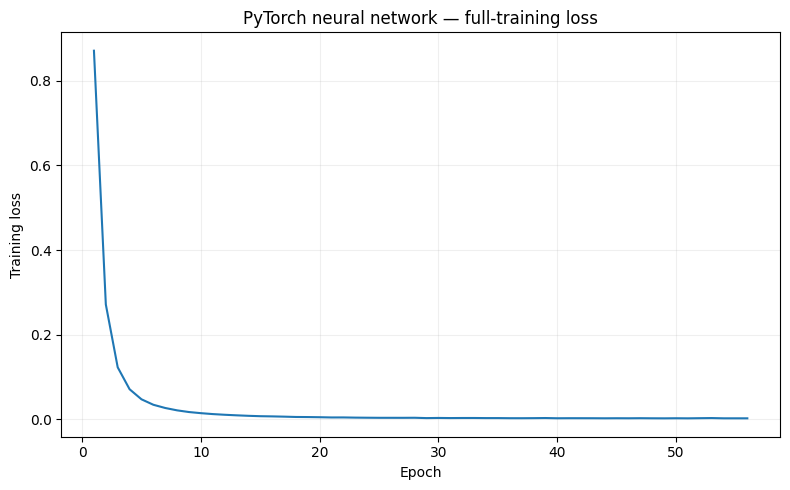

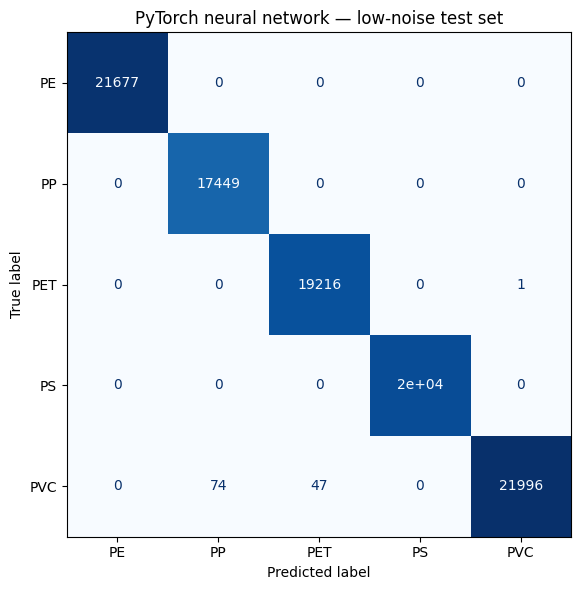


Test metrics:
test_accuracy: 0.9988
test_macro_precision: 0.9987
test_macro_recall: 0.9989
test_macro_f1: 0.9988

Trainable parameters: 7,365
Results saved to: /Users/williamronan/PythonTools/HyperspectralPVCSort/results/neural_network_pytorch_32


In [5]:
from pathlib import Path
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from scipy.ndimage import label
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. Configuration
# ============================================================

RESULTS_DIR = Path("results") / "neural_network_pytorch_32"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHANNELS = [f"ch.{i}" for i in range(1, 225)]
CLASS_NAMES = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}
CLASS_IDS = list(CLASS_NAMES)

SETTINGS = {
    "hidden_layers": [32],
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "max_epochs": 200,
    "patience": 20,
    "seed": 42
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Improves reproducibility, although devices may still differ.
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


set_seed(SETTINGS["seed"])

device = torch.device("cpu")
torch.set_num_threads(2)

print(f"Device: {device}", flush=True)

print(f"Device: {device}")
print("Architecture: 224 → 32 → 5")

# ============================================================
# 2. Dark-current correction and normalization
# ============================================================

wavelength_nm = (
    wavelength.set_index("channel")
    .loc[range(1, 225), "wavelength"]
    .to_numpy(dtype=float)
)

dark_values = darkcurrent[CHANNELS].to_numpy(dtype=float)

if not np.isfinite(dark_values).all():
    raise ValueError("Dark-current reference contains invalid values.")

dark_vector = dark_values.mean(axis=0)


def preprocess(frame):
    spectra = frame[CHANNELS].to_numpy(dtype=float)

    if not np.isfinite(spectra).all():
        raise ValueError("Spectra contain missing or non-finite values.")

    corrected = spectra - dark_vector
    minimum = corrected.min(axis=1, keepdims=True)
    value_range = np.ptp(corrected, axis=1, keepdims=True)

    if np.any(value_range == 0):
        raise ValueError("Constant spectra detected. Inspect before training.")

    normalized = (corrected - minimum) / value_range
    return normalized.astype(np.float32)


def get_labels(frame):
    values = pd.to_numeric(frame["class_id"], errors="raise").to_numpy()

    if not np.isin(values, CLASS_IDS).all():
        raise ValueError("Expected class labels 1–5.")

    return values.astype(np.int64)


X_train = preprocess(trainSet)
y_train = get_labels(trainSet)

# PyTorch cross-entropy uses class indices 0–4.
y_train_torch = y_train - 1

# ============================================================
# 3. Build the same spatial-cluster validation folds
# ============================================================

coords = trainSet[
    ["coord_lateral", "coord_driving"]
].to_numpy(dtype=float)

if not np.isfinite(coords).all() or not (coords % 1 == 0).all():
    raise ValueError("Grouping requires valid integer coordinates.")

coords = coords.astype(int)
offsets = coords - coords.min(axis=0)

occupancy = np.zeros(
    (offsets[:, 1].max() + 1, offsets[:, 0].max() + 1),
    dtype=bool
)
occupancy[offsets[:, 1], offsets[:, 0]] = True

cluster_grid, cluster_count = label(
    occupancy,
    structure=np.ones((3, 3), dtype=int)
)
groups = cluster_grid[offsets[:, 1], offsets[:, 0]]

group_table = pd.DataFrame({
    "cluster": groups,
    "class_id": y_train
})

if group_table.groupby("cluster")["class_id"].nunique().gt(1).any():
    raise ValueError("Some clusters contain multiple categories.")

object_table = (
    group_table.drop_duplicates("cluster")
    .sort_values("cluster")
    .reset_index(drop=True)
)

groups_per_class = (
    object_table["class_id"]
    .value_counts()
    .reindex(CLASS_IDS, fill_value=0)
)

n_splits = min(5, int(groups_per_class.min()))

if n_splits < 2:
    raise ValueError("Need at least two spatial clusters per category.")

object_cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=SETTINGS["seed"]
)

folds = []
validation_fold = np.full(len(trainSet), -1, dtype=int)

for fold_number, (fit_objects, val_objects) in enumerate(
    object_cv.split(object_table["cluster"], object_table["class_id"]),
    start=1
):
    fit_groups = object_table.iloc[fit_objects]["cluster"].to_numpy()
    val_groups = object_table.iloc[val_objects]["cluster"].to_numpy()

    fit_indices = np.flatnonzero(np.isin(groups, fit_groups))
    val_indices = np.flatnonzero(np.isin(groups, val_groups))

    if np.intersect1d(fit_groups, val_groups).size:
        raise ValueError("Cluster overlap between training and validation.")

    for indices in [fit_indices, val_indices]:
        if set(np.unique(y_train[indices])) != set(CLASS_IDS):
            raise ValueError("A fold is missing a category.")

    folds.append((fit_indices, val_indices))
    validation_fold[val_indices] = fold_number

pd.DataFrame({
    "row_position": np.arange(len(trainSet)),
    "cluster": groups,
    "class_id": y_train,
    "validation_fold": validation_fold
}).to_csv(RESULTS_DIR / "training_groups.csv", index=False)

print(f"Training rows: {len(X_train):,}")
print(f"Spatial clusters: {cluster_count}")
print(f"Validation folds: {n_splits}")

# ============================================================
# 4. Define the PyTorch neural network
# ============================================================

class SpectralMLP(nn.Module):
    def __init__(self, input_size=224, hidden_layers=(64, 32), classes=5):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_layers:
            layers.extend([
                nn.Linear(previous_size, hidden_size),
                nn.ReLU()
            ])
            previous_size = hidden_size

        # Output raw scores (logits), not probabilities.
        layers.append(nn.Linear(previous_size, classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def make_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(np.ascontiguousarray(X)),
        torch.from_numpy(np.ascontiguousarray(y))
    )
    return DataLoader(
        dataset,
        batch_size=SETTINGS["batch_size"],
        shuffle=shuffle,
        num_workers=0
    )


def new_model():
    return SpectralMLP(
        input_size=len(CHANNELS),
        hidden_layers=SETTINGS["hidden_layers"],
        classes=len(CLASS_IDS)
    ).to(device)


def train_one_epoch(model, loader, optimizer, loss_function):
    model.train()
    total_loss = 0.0
    total_rows = 0

    for batch_X, batch_y in loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_X)
        loss = loss_function(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_X)
        total_rows += len(batch_X)

    return total_loss / total_rows


def evaluate(model, loader, loss_function):
    model.eval()
    total_loss = 0.0
    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_X)
            total_loss += (
                loss_function(logits, batch_y).item() * len(batch_X)
            )

            true_labels.extend(batch_y.cpu().numpy())
            predicted_labels.extend(logits.argmax(dim=1).cpu().numpy())

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        predicted_labels,
        labels=range(5),
        average="macro",
        zero_division=0
    )

    return {
        "loss": total_loss / len(true_labels),
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1)
    }


# ============================================================
# 5. Validation and selection of training duration
# ============================================================

loss_function = nn.CrossEntropyLoss()
fold_results = []
all_history = []

cv_start = time.perf_counter()

for fold_number, (fit_indices, val_indices) in enumerate(folds, start=1):
    print(f"\nTraining validation fold {fold_number}/{n_splits}", flush=True)

    set_seed(SETTINGS["seed"])
    model = new_model()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=SETTINGS["learning_rate"],
        weight_decay=SETTINGS["weight_decay"]
    )

    fit_loader = make_loader(
        X_train[fit_indices],
        y_train_torch[fit_indices],
        shuffle=True
    )
    val_loader = make_loader(
        X_train[val_indices],
        y_train_torch[val_indices]
    )

    best_f1 = -1.0
    best_loss = float("inf")
    best_epoch = 0
    best_metrics = None
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, SETTINGS["max_epochs"] + 1):
        train_loss = train_one_epoch(
            model, fit_loader, optimizer, loss_function
        )
        validation = evaluate(model, val_loader, loss_function)

        history.append({
            "fold": fold_number,
            "epoch": epoch,
            "training_loss": train_loss,
            **{f"validation_{k}": v for k, v in validation.items()}
        })

        # Prefer higher macro F1; use lower loss to break ties.
        improved = (
            validation["macro_f1"] > best_f1 + 1e-8
            or (
                abs(validation["macro_f1"] - best_f1) <= 1e-8
                and validation["loss"] < best_loss - 1e-6
            )
        )

        if improved:
            best_f1 = validation["macro_f1"]
            best_loss = validation["loss"]
            best_epoch = epoch
            best_metrics = validation.copy()
            epochs_without_improvement = 0

            # Save a snapshot of this fold's best model.
            torch.save(
                {
                    key: value.detach().cpu().clone()
                    for key, value in model.state_dict().items()
                },
                RESULTS_DIR / f"fold_{fold_number}_best_weights.pt"
            )
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:3d} | train loss {train_loss:.4f} | "
                f"validation F1 {validation['macro_f1']:.4f}",
                flush=True
            )

        if epochs_without_improvement >= SETTINGS["patience"]:
            print(f"Early stopping at epoch {epoch}", flush=True)
            break

    fold_results.append({
        "fold": fold_number,
        "best_epoch": best_epoch,
        "epochs_run": epoch,
        "training_rows": len(fit_indices),
        "validation_rows": len(val_indices),
        **{f"validation_{k}": v for k, v in best_metrics.items()}
    })

    all_history.extend(history)

    # Save progress after every completed fold.
    pd.DataFrame(fold_results).to_csv(
        RESULTS_DIR / "cross_validation_results.csv", index=False
    )
    pd.DataFrame(all_history).to_csv(
        RESULTS_DIR / "validation_training_history.csv", index=False
    )

cv_seconds = time.perf_counter() - cv_start
cv_table = pd.DataFrame(fold_results)

print("\nValidation metrics at each fold's selected epoch:")
for metric in ["accuracy", "macro_precision", "macro_recall", "macro_f1"]:
    values = cv_table[f"validation_{metric}"]
    print(f"{metric}: {values.mean():.4f} ± {values.std(ddof=1):.4f}")

# Use the median selected epoch count for full-data training.
final_epochs = max(1, int(np.median(cv_table["best_epoch"])))
print(f"\nSelected full-training duration: {final_epochs} epochs")

# ============================================================
# 6. Train a fresh model on all of trainSet
# ============================================================

set_seed(SETTINGS["seed"])
final_model = new_model()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=SETTINGS["learning_rate"],
    weight_decay=SETTINGS["weight_decay"]
)

full_loader = make_loader(X_train, y_train_torch, shuffle=True)

final_history = []
fit_start = time.perf_counter()

for epoch in range(1, final_epochs + 1):
    training_loss = train_one_epoch(
        final_model, full_loader, optimizer, loss_function
    )
    final_history.append({
        "epoch": epoch,
        "training_loss": training_loss
    })

    if epoch == 1 or epoch % 10 == 0 or epoch == final_epochs:
        print(
            f"Full training epoch {epoch}/{final_epochs} | "
            f"loss {training_loss:.4f}",
            flush=True
        )

fit_seconds = time.perf_counter() - fit_start

loss_table = pd.DataFrame(final_history)
loss_table.to_csv(RESULTS_DIR / "training_loss.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(loss_table["epoch"], loss_table["training_loss"])
ax.set(
    xlabel="Epoch",
    ylabel="Training loss",
    title="PyTorch neural network — full-training loss"
)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss.png", dpi=300)
plt.show()
plt.close(fig)

# ============================================================
# 7. Evaluate on testSetLowNoise
# ============================================================

X_test = preprocess(testSetLowNoise)
y_test = get_labels(testSetLowNoise)

test_loader = make_loader(X_test, y_test - 1)

final_model.eval()
probability_batches = []
prediction_start = time.perf_counter()

with torch.no_grad():
    for batch_X, _ in test_loader:
        logits = final_model(batch_X.to(device))
        probabilities = torch.softmax(logits, dim=1)
        probability_batches.append(probabilities.cpu().numpy())

probabilities = np.concatenate(probability_batches, axis=0)
prediction_seconds = time.perf_counter() - prediction_start

# Convert PyTorch indices 0–4 back to original labels 1–5.
predictions = probabilities.argmax(axis=1) + 1

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    predictions,
    labels=CLASS_IDS,
    average="macro",
    zero_division=0
)

parameter_count = sum(
    parameter.numel() for parameter in final_model.parameters()
)

metrics = {
    "test_accuracy": float(accuracy_score(y_test, predictions)),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "validation_selected_macro_f1_mean": float(
        cv_table["validation_macro_f1"].mean()
    ),
    "validation_selected_macro_f1_std": float(
        cv_table["validation_macro_f1"].std(ddof=1)
    ),
    "validation_folds": n_splits,
    "training_clusters": int(cluster_count),
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "trainable_parameters": parameter_count,
    "final_epochs": final_epochs,
    "cross_validation_seconds": cv_seconds,
    "full_training_seconds": fit_seconds,
    "test_prediction_seconds": prediction_seconds,
    "device": str(device)
}

with open(RESULTS_DIR / "metrics.json", "w") as handle:
    json.dump(metrics, handle, indent=2)

with open(RESULTS_DIR / "model_settings.json", "w") as handle:
    json.dump(SETTINGS, handle, indent=2)

report = classification_report(
    y_test,
    predictions,
    labels=CLASS_IDS,
    target_names=list(CLASS_NAMES.values()),
    output_dict=True,
    zero_division=0
)
pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "row_position": np.arange(len(y_test)),
    "true_class": y_test,
    "predicted_class": predictions,
    "correct": predictions == y_test
})

for column, class_id in enumerate(CLASS_IDS):
    prediction_table[f"probability_{CLASS_NAMES[class_id]}"] = (
        probabilities[:, column]
    )

prediction_table.to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False
)

cm = confusion_matrix(y_test, predictions, labels=CLASS_IDS)

pd.DataFrame(
    cm,
    index=pd.Index(CLASS_NAMES.values(), name="true_category"),
    columns=pd.Index(CLASS_NAMES.values(), name="predicted_category")
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm,
    display_labels=list(CLASS_NAMES.values())
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("PyTorch neural network — low-noise test set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================
# 8. Save PyTorch weights and preprocessing references
# ============================================================

torch.save(
    {
        "model_state_dict": {
            key: value.detach().cpu().clone()
            for key, value in final_model.state_dict().items()
        },
        "input_size": len(CHANNELS),
        "hidden_layers": SETTINGS["hidden_layers"],
        "num_classes": len(CLASS_IDS),
        "settings": SETTINGS,
        "final_epochs": final_epochs,
        "class_names": CLASS_NAMES
    },
    RESULTS_DIR / "model_checkpoint.pt"
)

np.savez(
    RESULTS_DIR / "preprocessing.npz",
    dark_vector=dark_vector,
    wavelength_nm=wavelength_nm,
    channels=np.asarray(CHANNELS)
)

with open(RESULTS_DIR / "preprocessing.json", "w") as handle:
    json.dump({
        "dark_correction": "Mean dark-current reference per channel",
        "normalization": "Per-spectrum min-max after dark subtraction",
        "torch_target_encoding": "Original class_id minus 1",
        "torch_version": str(torch.__version__)
    }, handle, indent=2)

print("\nTest metrics:")
for metric in [
    "test_accuracy",
    "test_macro_precision",
    "test_macro_recall",
    "test_macro_f1"
]:
    print(f"{metric}: {metrics[metric]:.4f}")

print(f"\nTrainable parameters: {parameter_count:,}")
print(f"Results saved to: {RESULTS_DIR.resolve()}")